# A simple non-Poissonian example

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os
sys.path.append("/zfs/nrodd/NPTFit/Full_Testing_Baseline/")

import copy
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp

import config.bayesian_scan_models as bsm #module for performing scan
# import analysis_classes.fermi_analysis as fa  #module for analysing scan

%matplotlib inline

## Define the directories and physics variables for the scan

In [2]:
work_dir = "/zfs/nrodd/NPTFit/Full_Testing_Baseline"
psf_dir = work_dir + '/psf_dir/'

In [3]:
tag = 'Example'
run_tag = 'NPTF_test_en_8_16' 

In [4]:
# CTB min max used for plotting 3FGL
CTB_en_min = 8
CTB_en_max=16
nside=128

In [5]:
mask_type = '0.95' 
force_energy = True 
energy_bin_mask = 8 

## Now we will make an instance of bayesian_scan_models to setup the template scan

### Setting up the scan

In [6]:
iso_temp = [hp.ud_grade(np.load("../../Fermi_Data/Template_iso.npy"),nside,power=-2)]

In [7]:
fermi_data = hp.ud_grade(np.load("../../Fermi_Data/FermiData_counts.npy"),nside,power=-2)
fermi_exposure = hp.ud_grade(np.load("../../Fermi_Data/FermiData_exposure.npy"),nside,power=-2)
fermi_psc_mask = hp.ud_grade(np.load("../../Fermi_Data/FermiData_pscmask.npy"),nside,power=-2)

In [8]:
b = bsm.bayesian_scan_NPTF(tag=tag,nside=nside,work_dir=work_dir,psf_dir=psf_dir)
b.load_external_data([8,16], [fermi_data], [fermi_exposure])
b.make_mask_total(plane_mask=False,mask_ring = True,outer=2,lat=150)

In [9]:
temp_dict = {'iso': iso_temp}

In [10]:
b.add_new_template(temp_dict)
b.rebin_external_data(1)

Now let's add our Poissonian models

In [11]:
b.add_poiss_model('iso','$A_{iso}$',[-2,2],False)

In [12]:
b.add_non_poiss_model('iso',['$\\tilde A_{ps}$','$n_1$','$n_2$','$S_b^{(1)}$'],[[-6,6],[2.05,30],[-2,1.95],[0.05,30]],[True,False,False,False])

Now, we will initiate the NPTF.  We have 2 PS templates, so we use `b.initiate_2_ps_edep`.  There are also functions for initializing 1 PS and 3 PS.

In [13]:
f_ary, df_ary = np.load("../../Full_Testing/psf_dir/gauss_128_0.181.npy")

In [14]:
b.initiate_1_ps_edep([0.1812])

$A_{iso}$
0 [True, False, False, False]
1 [True, False, False, False]
2 [True, False, False, False]
3 [True, False, False, False]
The k_max_array is  [16.0]
The number of parameters is  5
The name of the PSF file is  /zfs/nrodd/NPTFit/Full_Testing_Baseline/psf_dir/f_ary-128-0.181-10.dat
just loading PSF ...


### Running the scan

In [15]:
b.perform_scan(run_tag=run_tag)

## Analysis

In [16]:
sys.path.append("/zfs/nrodd/NPTF/analysis_classes/")
import analysis_classes.fermi_analysis as fa  #module for analysing scan

In [17]:
outer_plot=10 #this is the outer radius for the spectrum analysis
kwargs_spectrum={'mask_ring': True, 'outer': 2, 'lat': 150}

In [18]:
cs=fa.compute_edep_spectra(b,run_tag,b.CTB_en_bins,**kwargs_spectrum)

In load_scan: polychord, minuit: False False
  analysing data from /zfs/nrodd/NPTFit/Full_Testing_Baselinechains/Example/NPTF_test_en_8_16/.txt
the medians are  [  1.18742868  -1.57720224  14.78612717  -0.45699332  22.7451546 ]
the medians (from chains) are  [  1.18742868  -1.57720224  14.78612717  -0.45699332  22.7451546 ]
the number of parameters is  5
Len of fixed params list:  0
self.poiss_comp_numbers:  {'iso-0': 0}


In [19]:
print 'iso PS: ', cs.return_intensity_arrays_non_poiss('iso',0)

iso PS:  [  2.35567855e-09   5.69969272e-09   9.03432856e-09]


In [20]:
print 'iso: ',cs.cs_array[0].return_poiss_intensity_conf_int('iso-0',quant = [0.16,0.5,0.84])

iso:  at comp  iso-0 log prior:  False intensity:  [  1.39541547e-08   1.68872318e-08   1.97539409e-08]
[  1.39541547e-08   1.68872318e-08   1.97539409e-08]


In [21]:
b.calculate_medians()

the medians are  [  1.18742868  -1.57720224  14.78612717  -0.45699332  22.7451546 ]
the medians (from chains) are  [  1.18742868  -1.57720224  14.78612717  -0.45699332  22.7451546 ]
the number of parameters is  5


In [22]:
pdnds = fa.plot_dnds(b,**kwargs_spectrum)

/zfs/nrodd/anaconda/lib/python2.7/site-packages/matplotlib/collections.py:590: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if self._edgecolors == str('face'):


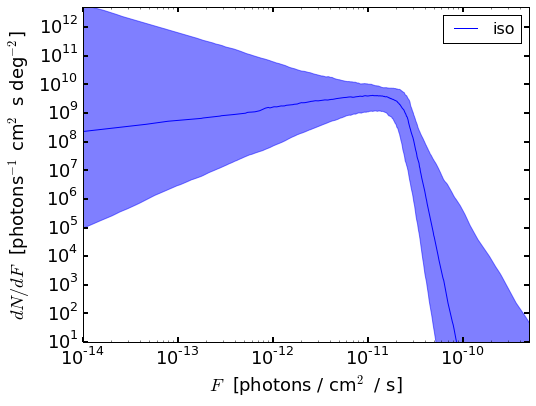

In [23]:
plt.figure(figsize=(8,6))
#plot medians
pdnds.plot_source_count_median('iso',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='blue',label='iso')

#plot band
pdnds.plot_source_count_band('iso',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='blue',label='iso',alpha=0.5)

plt.legend(fontsize=16) 

plt.yscale('log')
plt.xscale('log')
plt.xlim([1e-14,5e-10])
plt.ylim([1e1,5e12])

plt.tick_params(axis='x', length=5,width=2,labelsize=18)
plt.tick_params(axis='y',length=5,width=2,labelsize=18)
plt.xlabel('$F$  [photons / cm$^2$ / s]', fontsize=18)
plt.ylabel('$dN/dF$  [photons$^{-1}$ cm$^2$ s deg$^{-2}$]', fontsize=18)

plt.show()